# 03 - Spatial analysis by district, 2015-2025

**Questions:** can the 25 districts (gu) be ranked by PM2.5, or do the differences between stations come partly from how each station is measured? How does the population of each district change the picture of exposure, and how do roadside stations compare with the urban ones?

Each district has one **urban** monitoring station, so a district value is the value of its station. If a station moves or its instruments change, its level can change while the air of the district does not; the notebook checks that before comparing districts.

**Official station history:** table 19.1 of the [*2018 Seoul Air Quality Assessment Report*](https://news.seoul.go.kr/env/files/2021/01/60112177d83700.85894331.pdf) (2018년 서울 대기질 평가 보고서), transcribed to `data/reference/station_history.csv`: the year of the latest equipment replacement and relocation of each station up to 2019, without months. Changes after 2019 are not documented here.

## 1. Imports

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from seoul_air import config
from scipy.stats import fisher_exact

from seoul_air import population
from seoul_air.data import load_station_history
from seoul_air.report import save_key_figures
from seoul_air.sources import load_stations_reference
from seoul_air.station_levels import (agreed_shifts, change_around, detect_level_shifts, log_ratio,
                                      nearest_stations, neighbour_median, offset_from_city,
                                      offset_intervals, rest_of_city_mean, shuffle_blocks,
                                      station_outages, to_station_table)
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 140)
config.FIGURES.mkdir(parents=True, exist_ok=True)
config.METRICS.mkdir(parents=True, exist_ok=True)

In [2]:
daily = pd.read_parquet(config.DATA_PROCESSED / "air_daily_2015_2025.parquet")
hourly = pd.read_parquet(config.DATA_PROCESSED / "air_hourly_2015_2025.parquet", columns=["datetime", "district", "pm25"])
stations = load_stations_reference()
history = load_station_history()
daily["year"] = daily["date"].dt.year
daily["bad_or_worse"] = daily["pm25_grade"].isin(["Bad", "Very bad"]).where(daily["pm25"].notna())
pm25 = to_station_table(daily, "pm25")

## 2. District medians (descriptive, not a ranking)

The medians below describe what each station recorded. Sections 4 to 9 show why their order should not be read as a ranking of the air in each district.

In [3]:
by_district = daily.groupby("district").agg(
    pm25_median=("pm25", "median"),
    pm25_mean=("pm25", "mean"),
    pm25_bad_or_worse_days_pct=("bad_or_worse", lambda s: s.mean() * 100),
    no2_median=("no2", "median"),
    valid_pm25_days=("pm25", "count"),
).sort_values("pm25_median", ascending=False)
gap = by_district["pm25_median"].max() - by_district["pm25_median"].min()
print(f"Gap between the highest and lowest district median: {gap:.1f} ug/m3")
by_district.round(3)

Gap between the highest and lowest district median: 2.5 ug/m3


,pm25_median,pm25_mean,pm25_bad_or_worse_days_pct,no2_median,valid_pm25_days
district,,,,,
Geumcheon-gu,19.667,22.472,14.286,0.024,3899
Gwanak-gu,19.625,22.553,14.523,0.025,3856
Mapo-gu,19.511,22.641,15.125,0.023,3934
Yeongdeungpo-gu,19.400,22.572,14.286,0.024,3969
Gangdong-gu,19.333,22.143,14.101,0.023,3943
Yangcheon-gu,19.167,22.440,14.799,0.025,3926
Yongsan-gu,19.021,21.631,12.570,0.024,3954
Jongno-gu,19.000,21.964,13.604,0.024,3940
Dongjak-gu,18.958,22.152,14.078,0.023,3914


In [4]:
yearly = daily.pivot_table(index="district", columns="year", values="pm25", aggfunc="median")
ranks = yearly.rank(ascending=False).astype(int)
between_years = yearly.corr(method="spearman").where(~np.eye(len(yearly.columns), dtype=bool)).stack()
print(f"Spearman correlation of district medians between pairs of years: median {between_years.median():.2f}, "
      f"from {between_years.min():.2f} to {between_years.max():.2f}")
first = sorted(ranks.index[(ranks == 1).any(axis=1)])
print(f"Districts ranked first in at least one year: {len(first)}: {first}")
ranks.loc[ranks.mean(axis=1).sort_values().index].head(8)

Spearman correlation of district medians between pairs of years: median 0.19, from -0.37 to 0.79
Districts ranked first in at least one year: 8: ['Geumcheon-gu', 'Guro-gu', 'Gwanak-gu', 'Jung-gu', 'Nowon-gu', 'Yangcheon-gu', 'Yeongdeungpo-gu', 'Yongsan-gu']


year,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
district,,,,,,,,,,,
Geumcheon-gu,1,13,4,8,12,4,1,17,5,13,9
Gwanak-gu,4,1,3,2,2,22,19,12,4,3,22
Mapo-gu,2,7,2,4,3,14,21,20,10,5,7
Gangdong-gu,16,6,19,7,4,2,2,9,7,23,2
Nowon-gu,25,21,5,17,5,10,3,1,3,1,6
Jongno-gu,3,3,17,21,20,5,5,6,17,2,3
Yeongdeungpo-gu,6,9,23,1,1,15,9,14,18,4,5
Dongjak-gu,11,24,8,23,7,3,4,2,6,7,19


**Interpretation.** Over 2015-2025 the station medians are close: Geumcheon-gu has the highest (19.7 ug/m3) and Dobong-gu the lowest (17.2), a gap of only 2.5 ug/m3. Their order is not stable. The Spearman correlation of the district medians between two years has a median of 0.19 and ranges from -0.37 to 0.79, and 8 different districts rank first in at least one year; Nowon-gu, for example, is 25th in 2015 and 1st in 2022 and 2024.

## 3. Between-district vs day-to-day variation

In [5]:
corr = pm25.corr()
off_diag = corr.where(~np.eye(len(corr), dtype=bool)).stack()
print(f"Pairwise correlation of daily PM2.5 between districts: min {off_diag.min():.2f}, median {off_diag.median():.2f}")

v = daily.dropna(subset=["pm25"])
v = v.assign(month=v["date"].dt.month, year_month=v["date"].dt.to_period("M"))
total_var = v["pm25"].var()


def variance_share(group):
    return 1 - (v["pm25"] - v.groupby(group)["pm25"].transform("mean")).var() / total_var


# These groups are nested or overlapping, so the shares do not add up to 100%
shares = {
    "Date (each single day)": "date",
    "Month of each specific year": "year_month",
    "Calendar month (season)": "month",
    "Year": "year",
    "District": "district",
}
variance_pct = pd.Series({name: variance_share(group) * 100 for name, group in shares.items()})
variance_pct.round(1).to_frame("variance_share_%")

Pairwise correlation of daily PM2.5 between districts: min 0.91, median 0.95


,variance_share_%
Date (each single day),94.4
Month of each specific year,24.9
Calendar month (season),15.7
Year,4.2
District,0.3


**Interpretation.** Daily PM2.5 moves together across Seoul: the correlation between any two districts is at least 0.91 (median 0.95). The day accounts for 94.4% of the variance of station-day PM2.5, the month of a specific year for 24.9%, the calendar month for 15.7%, the year for 4.2% and the district for only 0.3%. Most of the variation is change from day to day that all districts share; differences between districts are the smallest part. Because PM2.5 behaves as a city-wide signal, the forecast of notebook 05 uses the city-wide mean as a feature.

## 4. Each station against the rest of the city

The **offset** of a station is its value minus the mean of the other stations on the same day. It removes the weather and the regional air that all stations share, and the bias of comparing stations measured on different days. If stations differed only by their location, each offset would stay roughly constant.

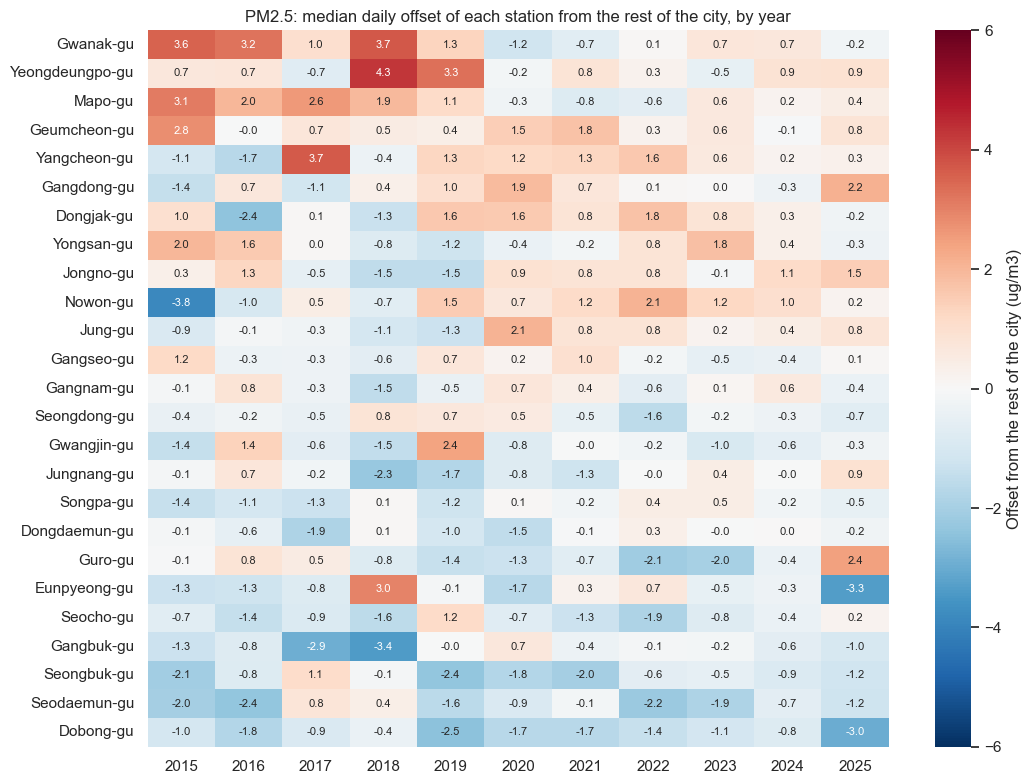

Range of each station's yearly offset: median 3.4 ug/m3, largest 6.3 (Eunpyeong-gu)
Stations whose yearly offset changes sign: 24 of 25


In [6]:
offset = offset_from_city(pm25)
weekly_offset = offset.resample("W").median()
annual_offset = offset.groupby(offset.index.year).median().T
order = annual_offset.mean(axis=1).sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(annual_offset.loc[order], cmap="RdBu_r", center=0, vmin=-6, vmax=6, annot=True, fmt=".1f",
            annot_kws={"size": 8}, cbar_kws={"label": "Offset from the rest of the city (ug/m3)"}, ax=ax)
ax.set_title("PM2.5: median daily offset of each station from the rest of the city, by year")
ax.set_xlabel("")
ax.set_ylabel("")
fig.tight_layout()
fig.savefig(config.FIGURES / "03_offset_heatmap.png", dpi=120)
plt.show()
swing = annual_offset.max(axis=1) - annual_offset.min(axis=1)
changes_sign = (annual_offset.max(axis=1) > 0) & (annual_offset.min(axis=1) < 0)
print(f"Range of each station's yearly offset: median {swing.median():.1f} ug/m3, largest {swing.max():.1f} ({swing.idxmax()})")
print(f"Stations whose yearly offset changes sign: {int(changes_sign.sum())} of {len(annual_offset)}")

**Interpretation.** No station keeps a fixed position. The yearly offset of a typical station spans 3.4 ug/m3 between its highest and lowest year (6.3 for Eunpyeong-gu), more than the 2.5 ug/m3 between the highest and lowest district medians, and the offset of 24 of the 25 stations changes sign at least once.

## 5. Official changes and data outages

The official table gives only years. Long outages of one station (at least 72 hours without PM2.5 while the rest of the network reports) can narrow down when a change happened, because moving a station or replacing its instruments interrupts the readings.

In [7]:
history.sort_values(["equipment_replaced", "district"], ascending=[False, True])

,district,installed,equipment_replaced,last_relocation,relocated_from
5,Dongdaemun-gu,1979,2019,2003,Sungin Girls' Middle School
22,Gangnam-gu,1978,2019,2012,Irwon-dong
20,Gwanak-gu,1979,2019,2001,Seoul National University ROTC building
6,Jungnang-gu,1984,2019,2009,Myeonmok drainage pump station
13,Mapo-gu,1997,2019,2018,Mapo Art Center
7,Seongbuk-gu,1978,2019,1988,Gireum 3-dong office
18,Yeongdeungpo-gu,1973,2019,2003,Mullae 2-dong office
9,Dobong-gu,1982,2018,2009,Banghak 1-dong office
11,Eunpyeong-gu,1995,2018,2012,Bulgwang 1-dong office
24,Gangdong-gu,1997,2018,<NA>,NaN


In [8]:
outages = station_outages(hourly, "pm25")
outages["year"] = outages["start"].dt.year
outages = outages.merge(history[["district", "equipment_replaced", "last_relocation"]], on="district")
outages["documented_that_year"] = (outages["year"].eq(outages["equipment_replaced"])
                                   | outages["year"].eq(outages["last_relocation"]).fillna(False)).astype(bool)
print(f"Outages of at least 72 hours: {len(outages)}, in {outages['district'].nunique()} stations")
print("By year:", outages["year"].value_counts().sort_index().to_dict())
print(f"In the same year as a documented change (2015-2019 only): {int(outages['documented_that_year'].sum())}")
changed = history["equipment_replaced"].isin([2018, 2019]) | history["last_relocation"].isin([2018, 2019])
had_outage = history["district"].isin(outages.loc[outages["year"].isin([2018, 2019]), "district"])
table = pd.crosstab(changed.map({True: "Change documented in 2018-2019", False: "No change documented in 2018-2019"}),
                    had_outage.map({True: "Outage in 2018-2019", False: "No outage in 2018-2019"}))
print(f"Fisher exact test, p = {fisher_exact(table)[1]:.4f}")
table.rename_axis(index=None, columns=None)

Outages of at least 72 hours: 55, in 24 stations
By year: {2015: 7, 2016: 9, 2017: 3, 2018: 8, 2019: 8, 2020: 3, 2021: 1, 2022: 5, 2023: 2, 2024: 2, 2025: 7}
In the same year as a documented change (2015-2019 only): 23
Fisher exact test, p = 0.0007


,No outage in 2018-2019,Outage in 2018-2019
Change documented in 2018-2019,4,14
No change documented in 2018-2019,7,0


**Interpretation.** Long outages and documented changes still go together: 23 of the 55 outages fall in the year of a documented change, and in 2018-2019 all 14 stations with an outage had a documented change while none of the 7 stations without one had an outage (Fisher exact test, p = 0.0007). Outages continue after 2019 (7 in 2025), when the official history used here stops, so later changes of station or equipment may be undocumented in this project.

## 6. Level shifts

A level shift is a lasting change of the offset. Detection works on the **monthly** median of `log(station / reference)` (11 years are too long for the weekly series of the earlier version), with circular binary segmentation, which also finds a change that later reverses. A stretch must differ from the rest by at least 10%, last at least 6 months and pass a test against block-shuffled series ($p \le 0.01$, blocks of 3 months).

A shift is accepted only if it appears against **two references**, the rest of the city and the 5 nearest stations, with the same sign and within about two months.

In [9]:
near = nearest_stations(stations, k=5)
SHIFT_OPTIONS = {"min_size": 6, "block": 3, "n_perm": 499}


def monthly_ratios(pollutant):
    table = to_station_table(daily, pollutant)
    city_ratio = log_ratio(table, rest_of_city_mean(table)).resample("MS").median()
    near_ratio = log_ratio(table, neighbour_median(table, near)).resample("MS").median()
    return city_ratio, near_ratio


def find_agreed(city_ratio, near_ratio, **options):
    options = {**SHIFT_OPTIONS, **options}
    found = []
    for district in city_ratio.columns:
        by_city = detect_level_shifts(city_ratio[district], **options)
        by_near = detect_level_shifts(near_ratio[district], **options)
        agreed = agreed_shifts(by_city, by_near, tolerance_weeks=9)
        if not agreed.empty:
            found.append(agreed.assign(district=district))
    return pd.concat(found, ignore_index=True) if found else pd.DataFrame()


ratios = {p: monthly_ratios(p) for p in config.POLLUTANTS}
shifts = pd.concat([find_agreed(*ratios[p]).assign(pollutant=p) for p in config.POLLUTANTS], ignore_index=True)
shifts["change_%"] = np.expm1(shifts["jump"]) * 100
shifts = shifts[["district", "pollutant", "date", "date_near", "change_%", "p_value"]]
print("Agreed shifts per pollutant:", shifts["pollutant"].value_counts().to_dict())
pm_shifts = shifts[shifts["pollutant"] == "pm25"].sort_values(["district", "date"]).reset_index(drop=True)
pm_shifts.round({"change_%": 1, "p_value": 4})

Agreed shifts per pollutant: {'so2': 26, 'co': 25, 'no2': 21, 'o3': 21, 'pm10': 15, 'pm25': 13}


,district,pollutant,date,date_near,change_%,p_value
0,Dongjak-gu,pm25,2019-07-01,2019-07-01,11.4,0.004
1,Eunpyeong-gu,pm25,2024-12-01,2024-12-01,-27.8,0.006
2,Eunpyeong-gu,pm25,2025-11-01,2025-11-01,38.5,0.006
3,Gwanak-gu,pm25,2015-02-01,2015-02-01,17.5,0.002
4,Gwanak-gu,pm25,2019-07-01,2019-05-01,-14.9,0.002
5,Jungnang-gu,pm25,2017-08-01,2017-09-01,-11.4,0.002
6,Jungnang-gu,pm25,2022-05-01,2022-05-01,12.8,0.002
7,Mapo-gu,pm25,2019-08-01,2019-07-01,-11.5,0.002
8,Mapo-gu,pm25,2022-09-01,2022-09-01,13.0,0.002
9,Nowon-gu,pm25,2015-04-01,2015-04-01,-33.3,0.002


In [10]:
# False-alarm check: the same rule on PM2.5 series whose months are shuffled in blocks
rng = np.random.default_rng(0)
city_ratio, near_ratio = ratios["pm25"]
false_alarms = []
for repeat in range(20):
    positions = shuffle_blocks(len(city_ratio), block=3, rng=rng)
    shuffled_city = city_ratio.iloc[positions].set_axis(city_ratio.index)
    shuffled_near = near_ratio.iloc[positions].set_axis(near_ratio.index)
    false_alarms.append(len(find_agreed(shuffled_city, shuffled_near, n_perm=199, seed=repeat)))
false_alarms = np.array(false_alarms)
print(f"Agreed PM2.5 shifts in the real data: {len(pm_shifts)} in {pm_shifts['district'].nunique()} stations")
print(f"Agreed PM2.5 shifts in 20 shuffled datasets: mean {false_alarms.mean():.1f}, "
      f"median {np.median(false_alarms):.0f}, max {false_alarms.max()}")
print(f"Shuffled datasets with at least as many shifts as the real data: {int((false_alarms >= len(pm_shifts)).sum())} of 20")

Agreed PM2.5 shifts in the real data: 13 in 7 stations
Agreed PM2.5 shifts in 20 shuffled datasets: mean 0.2, median 0, max 4
Shuffled datasets with at least as many shifts as the real data: 0 of 20


**Interpretation.** The rule accepts 13 PM2.5 level shifts in 7 stations, and none of the 20 shuffled datasets reaches 13 (their maximum is 4), so the shifts are unlikely to be chance. Their cause is not known. Three stations shift in 2019, the year of their equipment replacement (Gwanak-gu -14.9%, Mapo-gu -11.5% and Yeongdeungpo-gu -19.3%); others fall in years without documented changes, such as Eunpyeong-gu in 2024 and 2025 and Nowon-gu in 2015. A shift may also reflect a real change near a station.

## 7. Do documented changes move the offset?

For each outage in the year of a documented change (2015-2019), the 3 months after the outage are compared with the 3 months before it, for all six pollutants. The 95th percentile of such a change at any station on any date marks an unusual change.

In [11]:
events = outages[outages["documented_that_year"]].sort_values("end").groupby(["district", "year"]).tail(1)
rows = []
for event in events.itertuples():
    row = {"district": event.district, "after_outage_ending": event.end.date()}
    for pollutant in config.POLLUTANTS:
        row[pollutant] = np.expm1(change_around(ratios[pollutant][0][event.district], event.end, weeks=13)) * 100
    rows.append(row)
study = pd.DataFrame(rows).set_index(["district", "after_outage_ending"]).sort_index(level=1)
typical = {}
for pollutant in config.POLLUTANTS:
    monthly = ratios[pollutant][0]
    changes = [abs(change_around(monthly[d], date, weeks=13)) for d in monthly.columns for date in monthly.index[3:-3]]
    typical[pollutant] = np.expm1(np.nanpercentile(changes, 95)) * 100
print("95th percentile of the absolute change, in %:", {k: round(float(v), 1) for k, v in typical.items()})
unusual = study.abs() > pd.Series(typical)
print(f"Changes beyond that level: {int(unusual.to_numpy().sum())} of {unusual.size} (chance alone gives about 5%)")
print("By pollutant:", {k: int(v) for k, v in unusual.sum().items()}, "of", len(unusual), "events")
study.round(1)

95th percentile of the absolute change, in %: {'so2': 33.1, 'no2': 23.1, 'co': 27.5, 'o3': 21.5, 'pm10': 18.8, 'pm25': 26.6}
Changes beyond that level: 9 of 120 (chance alone gives about 5%)
By pollutant: {'so2': 1, 'no2': 1, 'co': 4, 'o3': 1, 'pm10': 1, 'pm25': 1} of 20 events


,,so2,no2,co,o3,pm10,pm25
district,after_outage_ending,,,,,,
Yangcheon-gu,2015-09-17,-22.6,8.7,18.5,-2.4,9.3,42.7
Gangbuk-gu,2015-09-18,-10.8,4.1,41.1,9.1,3.2,9.6
Geumcheon-gu,2015-09-18,-17.6,1.3,11.0,17.3,-3.7,-0.7
Dongjak-gu,2016-10-06,-2.5,1.2,3.2,15.4,3.5,14.0
Jongno-gu,2016-10-06,-4.8,21.4,37.9,17.5,6.2,9.5
Jung-gu,2016-10-21,-14.9,10.5,-11.9,-2.9,-9.5,-4.4
Gangbuk-gu,2016-12-15,2.7,-17.6,-7.8,19.4,-3.8,-10.0
Seocho-gu,2018-03-05,-19.7,9.1,-11.8,14.9,-1.8,-8.6
Guro-gu,2018-03-06,-22.2,21.6,-27.6,43.4,-2.9,-12.8


**Interpretation.** Documented changes still leave no common mark on PM2.5: across 20 events, 9 of the 120 changes exceed the 95th percentile of what any station shows on any date (about 5% would be expected by chance), and only 1 of them is a PM2.5 change (Yangcheon-gu, +42.7% after an outage in September 2015). Relocations and equipment replacements are therefore not shown to bias PM2.5 by a measurable amount, although a change of about 10% would not stand out from the noise.

## 8. The case of Yeongdeungpo-gu

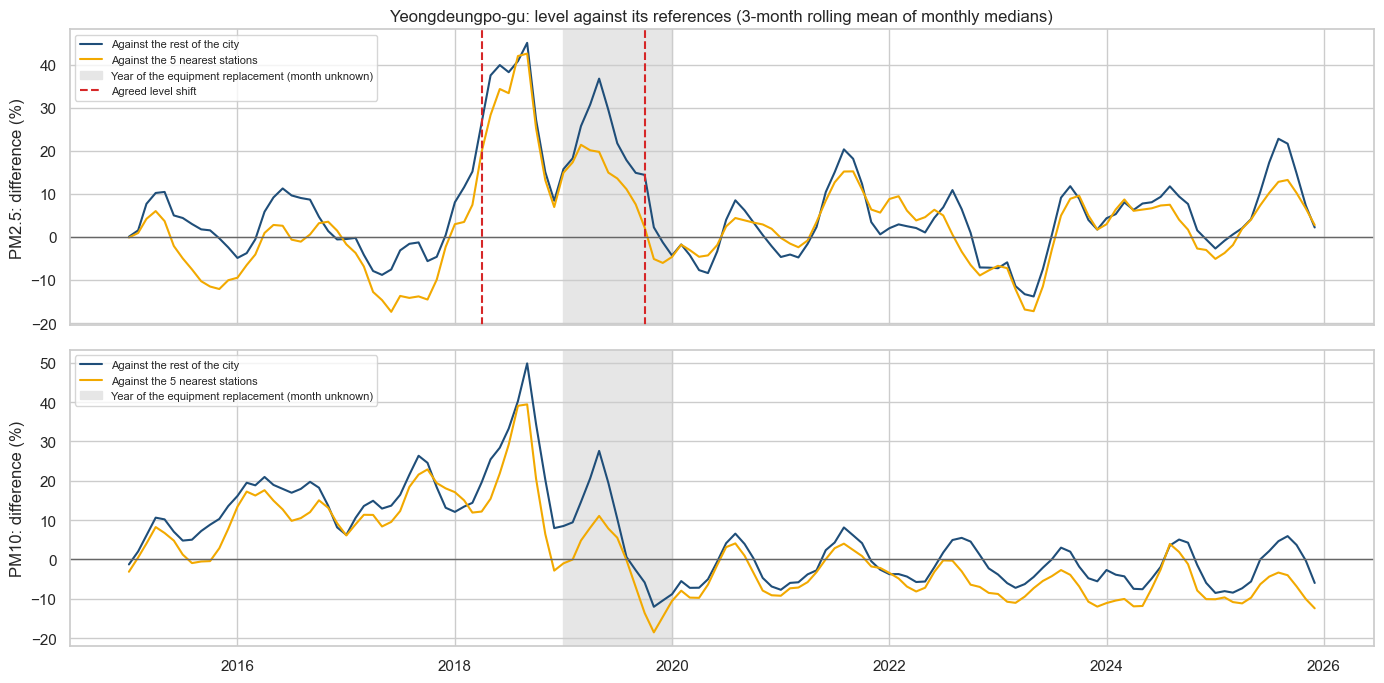

Difference from the rest of the city by year (%):


date,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
so2,4.6,-21.4,2.6,17.8,-14.8,-1.5,-7.2,0.1,-0.3,0.0,-3.9
no2,-9.6,-14.9,-0.1,-3.0,13.2,10.9,15.2,12.4,17.0,12.2,13.8
co,22.7,25.1,30.0,16.1,-12.3,5.5,13.2,4.3,-0.7,-6.7,-4.2
o3,-3.6,-1.7,-1.5,-6.8,-8.1,-6.3,-7.5,-6.1,-2.1,2.6,0.4
pm10,6.8,17.5,15.8,24.5,5.4,-2.3,-0.4,-0.9,-3.1,-2.4,-2.4
pm25,3.6,3.8,-3.9,25.5,18.1,-0.5,5.1,1.7,-2.1,6.5,8.0


In [12]:
name = "Yeongdeungpo-gu"
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
for ax, pollutant, label in zip(axes, ["pm25", "pm10"], ["PM2.5", "PM10"]):
    city_ratio, near_ratio = ratios[pollutant]
    ax.plot(np.expm1(city_ratio[name].rolling(3, center=True, min_periods=2).mean()) * 100,
            color="#1f4e79", label="Against the rest of the city")
    ax.plot(np.expm1(near_ratio[name].rolling(3, center=True, min_periods=2).mean()) * 100,
            color="#f2a900", label="Against the 5 nearest stations")
    ax.axhline(0, color="0.4", lw=1)
    ax.axvspan(pd.Timestamp("2019-01-01"), pd.Timestamp("2019-12-31"), color="0.9", zorder=0,
               label="Year of the equipment replacement (month unknown)")
    for date in shifts[(shifts["district"] == name) & (shifts["pollutant"] == pollutant)]["date"]:
        ax.axvline(date, color="#d62728", ls="--", label="Agreed level shift")
    handles, labels = ax.get_legend_handles_labels()
    unique = dict(zip(labels, handles))
    ax.legend(unique.values(), unique.keys(), fontsize=8, loc="upper left")
    ax.set_ylabel(f"{label}: difference (%)")
axes[0].set_title(f"{name}: level against its references (3-month rolling mean of monthly medians)")
fig.tight_layout()
fig.savefig(config.FIGURES / "03_yeongdeungpo_case.png", dpi=120)
plt.show()
case_years = pd.DataFrame({p: np.expm1(ratios[p][0][name].groupby(ratios[p][0].index.year).mean()) * 100
                           for p in config.POLLUTANTS})
print("Difference from the rest of the city by year (%):")
case_years.T.round(1)

**Interpretation.** With 11 years the case of Yeongdeungpo-gu is clearer. Its PM2.5 was close to the rest of the city in 2015-2017, 25.5% above it in 2018 and 18.1% in 2019, and back to -0.5% in 2020; the two agreed shifts are in April 2018 (+24.0%) and October 2019 (-19.3%). PM10 shows the same excess in 2018 (24.5%) and is close to the city from 2020. The excess therefore ends in the year of the equipment replacement, which fits an instrument effect, but the station history gives no month or instrument, so the cause remains unconfirmed. NO2 at this station stays 10% to 17% above the city from 2019, a separate pattern.

## 9. A comparison that does not overstate the differences

Instead of a ranking, each station gets a category from its weekly offset from the rest of the city:

- **Not comparable:** relocated during 2015-2025 according to the official history (known up to 2019), or with an agreed PM2.5 level shift.
- **Above / Below the rest of the city:** the 95% interval of the offset excludes zero and the yearly mean offset has the same sign in at least 9 of the 11 years.
- **No consistent difference:** everything else.

The intervals resample blocks of 4 weeks and keep all stations of a week together.

In [13]:
comparison = offset_intervals(weekly_offset, n_boot=2000, block=4)
offset_by_year = offset.groupby(offset.index.year).mean().T
positive_years = (offset_by_year > 0).sum(axis=1)
negative_years = (offset_by_year < 0).sum(axis=1)
relocated = set(history.loc[history["last_relocation"].between(2015, 2025), "district"])
shifted = set(pm_shifts["district"])


def category(row):
    if row.name in relocated or row.name in shifted:
        return "Not comparable"
    if row["offset_low"] > 0 and positive_years[row.name] >= 9:
        return "Above the rest of the city"
    if row["offset_high"] < 0 and negative_years[row.name] >= 9:
        return "Below the rest of the city"
    return "No consistent difference"


comparison["category"] = comparison.apply(category, axis=1)
comparison["reason"] = ["Relocated and level shift" if d in relocated and d in shifted else
                        "Relocated" if d in relocated else "Level shift" if d in shifted else ""
                        for d in comparison.index]
comparison = comparison.sort_values("offset", ascending=False)
comparison.to_csv(config.METRICS / "03_station_comparison.csv")
print(comparison["category"].value_counts().to_string())
print(f"\nMedian width of the 95% rank interval: {(comparison['rank_high'] - comparison['rank_low']).median():.0f} places of 25")
comparison.round(2)

category
Not comparable                11
No consistent difference      10
Above the rest of the city     2
Below the rest of the city     2

Median width of the 95% rank interval: 6 places of 25


,offset,offset_low,offset_high,rank_low,rank_high,category,reason
district,,,,,,,
Yeongdeungpo-gu,1.04,0.67,1.42,1.0,7.00,Not comparable,Level shift
Mapo-gu,1.04,0.67,1.39,1.0,7.00,Not comparable,Relocated and level shift
Gwanak-gu,1.03,0.63,1.47,1.0,7.00,Not comparable,Level shift
Geumcheon-gu,0.96,0.66,1.24,1.0,6.00,Above the rest of the city,
Yangcheon-gu,0.87,0.48,1.28,1.0,7.00,Above the rest of the city,
Dongjak-gu,0.62,0.29,0.95,3.0,9.00,Not comparable,Level shift
Gangdong-gu,0.57,0.22,0.93,3.0,10.00,No consistent difference,
Jongno-gu,0.52,0.13,0.91,4.0,11.00,No consistent difference,
Nowon-gu,0.35,-0.04,0.75,6.0,13.00,Not comparable,Level shift


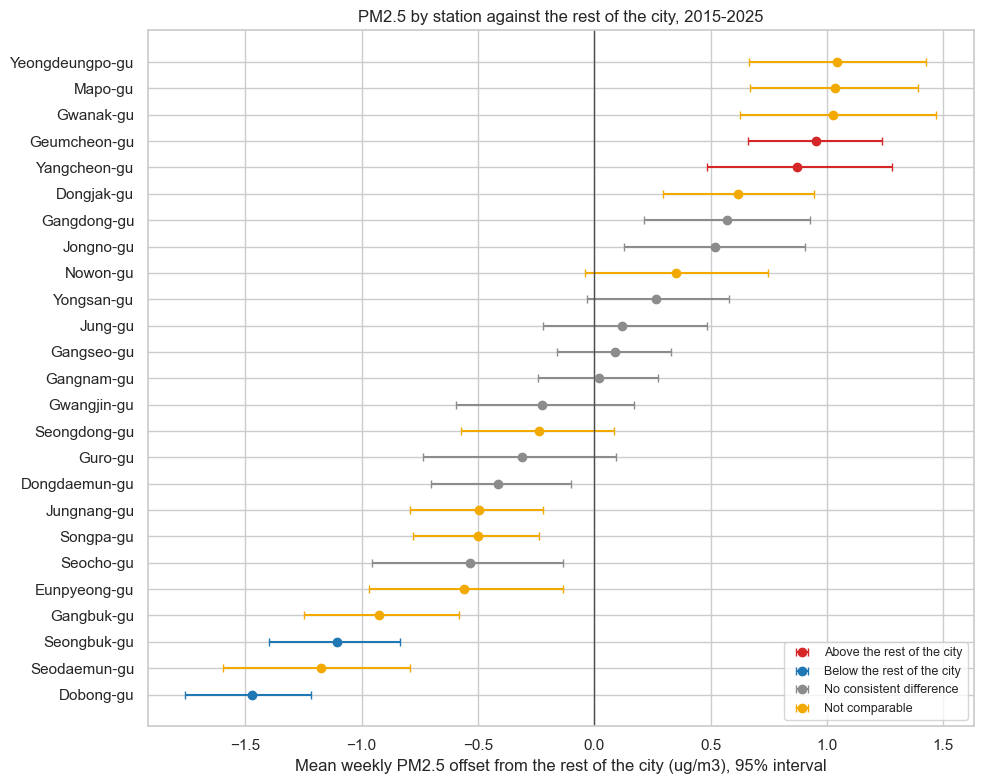

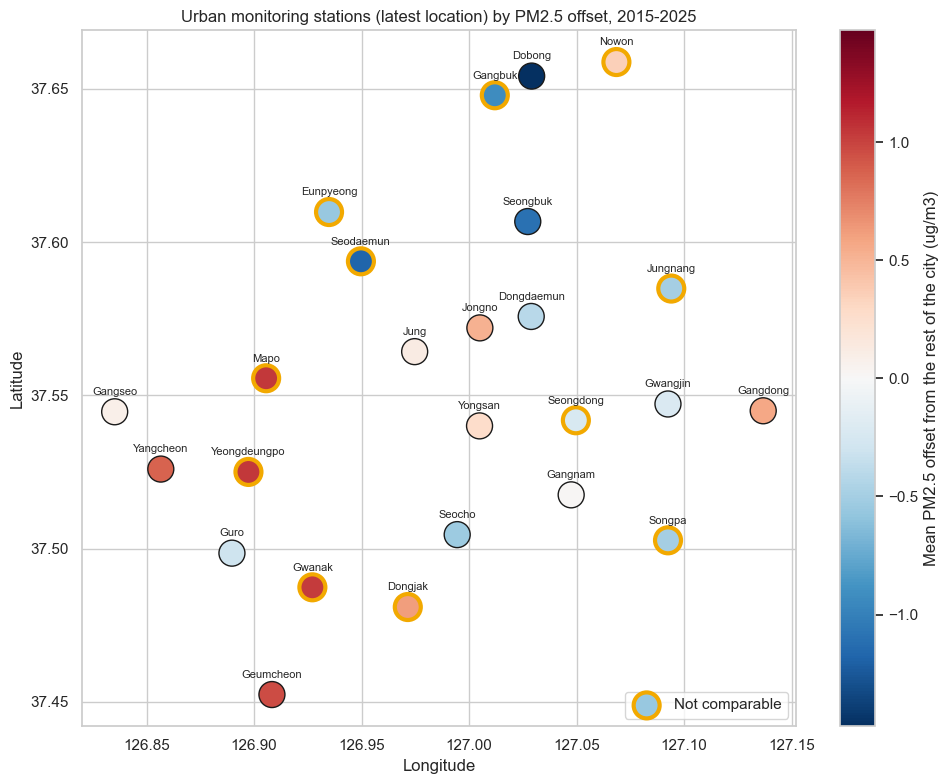

In [14]:
colors = {"Above the rest of the city": "#d62728", "Below the rest of the city": "#1f77b4",
          "No consistent difference": "0.55", "Not comparable": "#f2a900"}
fig, ax = plt.subplots(figsize=(10, 8))
c = comparison.iloc[::-1]
positions = np.arange(len(c))
for label, color in colors.items():
    mask = (c["category"] == label).to_numpy()
    ax.errorbar(c["offset"][mask].to_numpy(), positions[mask], fmt="o", color=color, capsize=3, label=label,
                xerr=[(c["offset"] - c["offset_low"])[mask].to_numpy(), (c["offset_high"] - c["offset"])[mask].to_numpy()])
ax.axvline(0, color="0.3", lw=1)
ax.set_yticks(positions)
ax.set_yticklabels(c.index)
ax.set_xlabel("Mean weekly PM2.5 offset from the rest of the city (ug/m3), 95% interval")
ax.set_title("PM2.5 by station against the rest of the city, 2015-2025")
ax.legend(loc="lower right", fontsize=9)
fig.tight_layout()
fig.savefig(config.FIGURES / "03_station_offsets.png", dpi=120)
plt.show()

m = stations.merge(comparison, left_on="district", right_index=True)
fig, ax = plt.subplots(figsize=(10, 8))
limit = m["offset"].abs().max()
regular = m[m["category"] != "Not comparable"]
flagged = m[m["category"] == "Not comparable"]
sc = ax.scatter(regular["longitude"], regular["latitude"], c=regular["offset"], s=350, cmap="RdBu_r",
                vmin=-limit, vmax=limit, edgecolor="k")
ax.scatter(flagged["longitude"], flagged["latitude"], c=flagged["offset"], s=350, cmap="RdBu_r",
           vmin=-limit, vmax=limit, edgecolor="#f2a900", linewidth=3, label="Not comparable")
for _, r in m.iterrows():
    ax.annotate(r["district"].replace("-gu", ""), (r["longitude"], r["latitude"]),
                textcoords="offset points", xytext=(0, 12), ha="center", fontsize=8)
fig.colorbar(sc, ax=ax, label="Mean PM2.5 offset from the rest of the city (ug/m3)")
ax.set_title("Urban monitoring stations (latest location) by PM2.5 offset, 2015-2025")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(config.FIGURES / "03_station_map.png", dpi=120)
plt.show()

**Interpretation.** With intervals instead of a ranking: **11 stations are not comparable** (5 were relocated in 2016 or 2018, the others have a level shift), **10 show no consistent difference**, and only 4 keep a difference over at least 9 of the 11 years: Geumcheon-gu (+0.96 ug/m3) and Yangcheon-gu (+0.87) above the rest of the city, Seongbuk-gu (-1.10) and Dobong-gu (-1.47) below. These differences are about one or two years of the city's decline (0.76 ug/m3 a year). The median 95% interval of a rank spans 6 places of 25. **This dataset does not support a ranking of districts by PM2.5.**

## 10. Population-weighted exposure

A city mean gives every district the same weight. Exposure weights each district's value by the number of people who live there, using the official resident population at the end of each year (Ministry of the Interior and Safety, `seoul_air.population`). A district's value is still the value of its one station, with the caveats above.

In [15]:
population.download_population()
pop = population.load_population()
print("Seoul population, end of 2015 and 2025:", f"{pop[pop.year == 2015]['population'].sum():,}",
      f"{pop[pop.year == 2025]['population'].sum():,}")
station_year = daily.groupby(["year", "district"])[["pm25", "pm10", "no2", "o3"]].mean().reset_index()
station_year = station_year.merge(pop, on=["year", "district"], validate="one_to_one")
rows = []
for year, group in station_year.groupby("year"):
    row = {"year": year}
    for p in ["pm25", "pm10", "no2", "o3"]:
        row[f"{p}_unweighted"] = group[p].mean()
        row[f"{p}_weighted"] = population.population_weighted_mean(group[p], group["population"])
    rows.append(row)
exposure = pd.DataFrame(rows).set_index("year")
for p in ["pm25", "pm10", "no2", "o3"]:
    exposure[f"{p}_difference"] = exposure[f"{p}_weighted"] - exposure[f"{p}_unweighted"]
print("Largest |weighted - unweighted| over the years:",
      {p: round(float(exposure[f'{p}_difference'].abs().max()), 4) for p in ["pm25", "pm10", "no2", "o3"]})
above = station_year["pm25"] > station_year.groupby("year")["pm25"].transform("mean")
share_people = (station_year.assign(above_population=station_year["population"].where(above, 0))
                .groupby("year")[["above_population", "population"]].sum())
share_people = 100 * share_people["above_population"] / share_people["population"]
print("People living in districts above the city mean of PM2.5 (%):", share_people.round(1).to_dict())
by_category = comparison[["category"]].join(pop[pop["year"] == 2025].set_index("district")["population"])
print("Population of 2025 by station category:", by_category.groupby("category")["population"].sum().to_dict())
exposure[["pm25_unweighted", "pm25_weighted", "pm25_difference", "no2_unweighted", "no2_weighted"]].round(4)

Seoul population, end of 2015 and 2025: 10,022,181 9,299,548
Largest |weighted - unweighted| over the years: {'pm25': 0.165, 'pm10': 0.528, 'no2': 0.0002, 'o3': 0.0002}
People living in districts above the city mean of PM2.5 (%): {2015: 38.8, 2016: 41.0, 2017: 46.8, 2018: 39.1, 2019: 54.3, 2020: 46.3, 2021: 49.0, 2022: 52.0, 2023: 47.3, 2024: 48.3, 2025: 52.6}
Population of 2025 by station category: {'Above the rest of the city': 648378, 'Below the rest of the city': 722458, 'No consistent difference': 3537580, 'Not comparable': 4391132}


,pm25_unweighted,pm25_weighted,pm25_difference,no2_unweighted,no2_weighted
year,,,,,
2015,23.2515,23.0993,-0.1522,0.0322,0.0319
2016,26.1786,26.0590,-0.1196,0.0314,0.0313
2017,24.5683,24.5763,0.0080,0.0296,0.0295
2018,22.8047,22.8934,0.0888,0.0281,0.0281
2019,24.9769,25.1419,0.1650,0.0281,0.0282
2020,20.7097,20.6381,-0.0716,0.0238,0.0241
2021,19.8488,19.8327,-0.0162,0.0236,0.0237
2022,18.3714,18.3900,0.0186,0.0209,0.0210
2023,19.6867,19.7304,0.0437,0.0204,0.0205


**Interpretation.** Weighting by population barely changes the city's exposure: population-weighted and unweighted PM2.5 differ by at most 0.165 ug/m3 in any year (0.528 for PM10 and 0.0002 ppm for NO2 and O3). The share of residents who live in districts above the city mean of PM2.5 varies from 38.8% in 2015 to 54.3% in 2019 without a pattern, and the 4 stations with a consistent difference cover 648,378 residents above and 722,458 below the rest of the city in 2025. Because the districts differ little and their differences are unstable, the exposure of the average resident follows the city level. Seoul's registered population fell from 10,022,181 to 9,299,548 over the period.

## 11. Roadside stations

Seoul also runs roadside stations (도로변대기) next to major roads. The official Seoul files used here (OA-15526, OA-2221) contain only the 25 urban stations (도시대기), so every analysis above is urban. The AirKorea final data of 2024 contains both networks; `tools/seoul_networks_2024.py` extracted the annual means of every Seoul station into `data/reference/seoul_stations_by_network_2024.csv`.

In [16]:
networks = pd.read_csv(config.ROOT / "data" / "reference" / "seoul_stations_by_network_2024.csv", dtype={"code": str})
networks["in_project_data"] = networks["code"].isin(set(stations["airkorea_code"]))
print(networks.groupby(["network_en", "in_project_data"]).size().to_string())
network_means = networks.groupby("network_en")[["pm25", "pm10", "no2", "o3"]].mean()
roadside_vs_urban = 100 * (network_means.loc["roadside"] / network_means.loc["urban"] - 1)
print("Roadside mean relative to the urban mean, 2024 (%):", roadside_vs_urban.round(1).to_dict())
networks.groupby("network_en")[["pm25", "pm10", "no2", "o3"]].agg(["mean", "median"]).round(4)

network_en  in_project_data
roadside    False              15
urban       True               25
Roadside mean relative to the urban mean, 2024 (%): {'pm25': 2.3, 'pm10': 10.9, 'no2': 41.2, 'o3': -20.8}


pm25              pm10              no2              o3        
               mean   median     mean   median    mean  median    mean  median
network_en                                                                    
roadside    17.9536  17.7332  34.7438  34.9332  0.0265  0.0266  0.0263  0.0266
urban       17.5505  17.5277  31.3183  31.0274  0.0188  0.0196  0.0332  0.0332

**Interpretation.** The project data has no roadside station: the 25 stations it uses are all urban, and the 15 roadside stations of Seoul are only in the AirKorea final data. In 2024 the roadside stations recorded 41.2% more NO2, 10.9% more PM10 and 2.3% more PM2.5 than the urban stations, and 20.8% less O3. This pattern is consistent with traffic emissions next to the roads, with NO from exhaust consuming ozone. The analysis of this project describes the urban background; people who spend time next to major roads breathe air with more NO2 than these figures show.

## 12. Key figures

In [17]:
save_key_figures("03", {
    "variance_share_pct": variance_pct.to_dict(),
    "min_pairwise_correlation": off_diag.min(),
    "spearman_between_years": [between_years.min(), between_years.median(), between_years.max()],
    "median_gap_between_district_medians": gap,
    "median_yearly_offset_range": swing.median(),
    "categories": comparison["category"].value_counts().to_dict(),
    "pm25_shifts": len(pm_shifts),
    "exposure_pm25_max_abs_difference": exposure["pm25_difference"].abs().max(),
    "roadside_vs_urban_pct_2024": roadside_vs_urban.to_dict(),
    "roadside_stations": int((networks["network_en"] == "roadside").sum()),
})
print((config.METRICS / "03_key_figures.json").read_text())

{
  "categories": {
    "Above the rest of the city": 2,
    "Below the rest of the city": 2,
    "No consistent difference": 10,
    "Not comparable": 11
  },
  "exposure_pm25_max_abs_difference": 0.16502951704888602,
  "median_gap_between_district_medians": 2.492753623188406,
  "median_yearly_offset_range": 3.362269041345126,
  "min_pairwise_correlation": 0.9110065135783199,
  "pm25_shifts": 13,
  "roadside_stations": 15,
  "roadside_vs_urban_pct_2024": {
    "no2": 41.21640509690074,
    "o3": -20.84909607102886,
    "pm10": 10.93763714752274,
    "pm25": 2.296897278887311
  },
  "spearman_between_years": [
    -0.3743747872346499,
    0.18769230769230769,
    0.7936876870666204
  ],
  "variance_share_pct": {
    "Calendar month (season)": 15.674215514061974,
    "Date (each single day)": 94.35557884338985,
    "District": 0.29535568007851287,
    "Month of each specific year": 24.914674639553347,
    "Year": 4.169594208548122
  }
}

